In [31]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

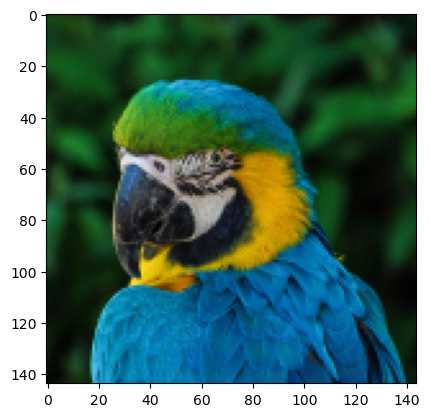

In [32]:
image = cv2.imread('test.png')
plt.imshow(image[:,:,::-1]); plt.show()

In [33]:
# Get RGB histograms and grayscale histogram using OpenCV
# params: image, channel, mask, num_bins, ranges
hist_blue = cv2.calcHist([image], [0], None, [256], [0, 256])
hist_green = cv2.calcHist([image], [1], None, [256], [0, 256])
hist_red = cv2.calcHist([image], [2], None, [256], [0, 256])

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
hist_gray = cv2.calcHist([gray], [0], None, [256], [0, 256])


In [34]:
# Get RGB histograms and grayscale histogram using numpy
# params: image, num_bins, ranges
hist_blue_np, bins_blue = np.histogram(image[:,:,0], 256, [0, 256])
hist_green_np, bins_green = np.histogram(image[:,:,1], 256, [0, 256])
hist_red_np, bins_red = np.histogram(image[:,:,2], 256, [0, 256])
hist_gray_np, bins_gray = np.histogram(gray, 256, [0, 256])


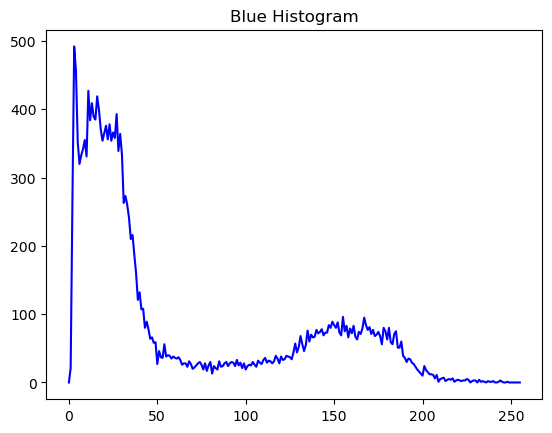

In [35]:
# Plot histograms as line plot, one at a time
plt.plot(hist_blue, color='blue')
plt.title('Blue Histogram')
plt.show()

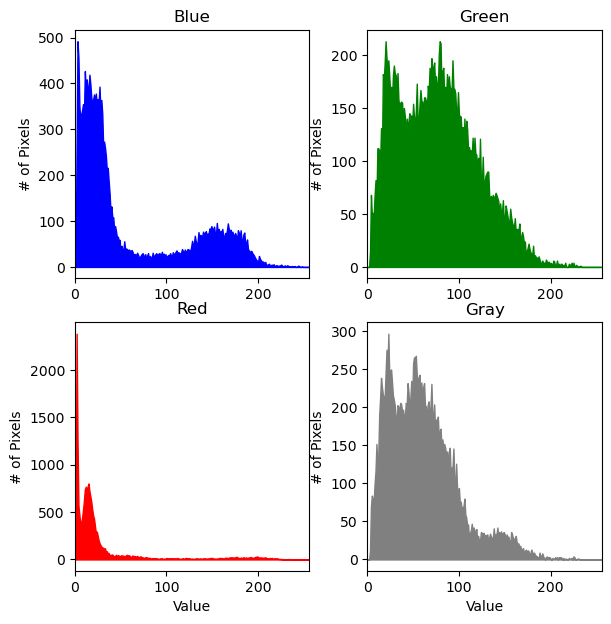

In [36]:
# Plot histograms in 2x2 grid
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(6, 6))
fig.tight_layout()

axes[0,0].set_title('Blue')
#axes[0,0].set_xlabel('Value')
axes[0,0].set_ylabel('# of Pixels')
x = np.arange(256)
axes[0,0].set_xlim([0, 256])
axes[0,0].fill_between(x,hist_blue[:,0], color='b')

axes[1,0] = plt.subplot(2,2,2)
axes[1,0].set_title('Green')
#axes[1,0].set_xlabel('Value')
axes[1,0].set_ylabel('# of Pixels')
x = np.arange(256)
axes[1,0].set_xlim([0, 256])
axes[1,0].fill_between(x,hist_green[:,0], color='g')

axes[0,1] = plt.subplot(2,2,3)
axes[0,1].set_title('Red')
axes[0,1].set_xlabel('Value')
axes[0,1].set_ylabel('# of Pixels')
axes[0,1].set_xlim([0, 256])
x = np.arange(256)
axes[0,1].fill_between(x,hist_red[:,0], color='r')

axes[1,1] = plt.subplot(2,2,4)
axes[1,1].set_title('Gray')
axes[1,1].set_xlabel('Value')
axes[1,1].set_ylabel('# of Pixels')
axes[1,1].set_xlim([0, 256])
x = np.arange(256)
axes[1,1].fill_between(x,hist_gray[:,0], color='gray')

plt.show()

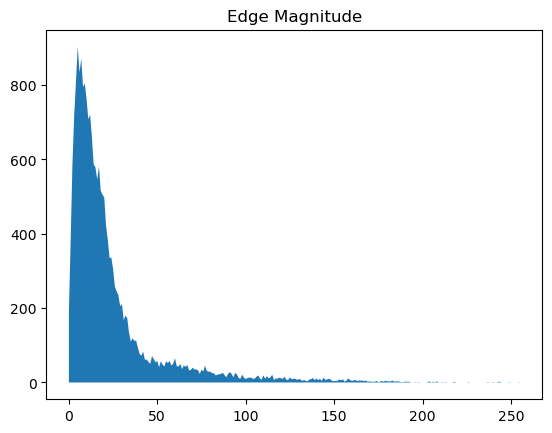

In [37]:
# Make histogram of gradient magnitude
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
sobel = np.sqrt(sobelx**2 + sobely**2)
sobel = sobel / sobel.max() * 255
sobel = sobel.astype(np.uint8)

hist_sobel = cv2.calcHist([sobel], [0], None, [256], [0, 256])
x = np.arange(256)
plt.fill_between(x,hist_sobel[:,0])
plt.title('Edge Magnitude')
plt.show()


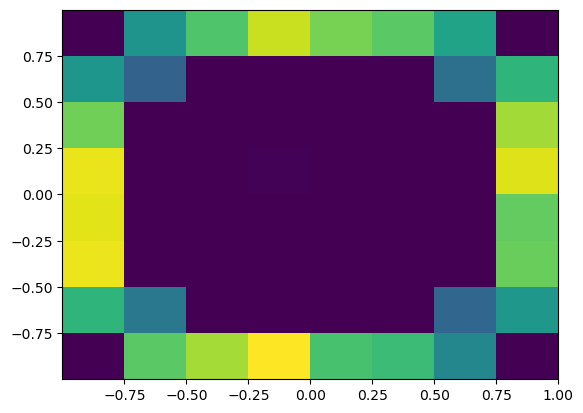

In [38]:
# Make 2D histogram of gradients for visualization
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)

sobel_mag = np.sqrt(sobelx**2 + sobely**2)

sobelx = sobelx / (sobel_mag + 1e-6)
sobely = sobely / (sobel_mag + 1e-6)

plt.hist2d(sobelx.flatten(), sobely.flatten(), bins=8);plt.show()

<BarContainer object of 8 artists>

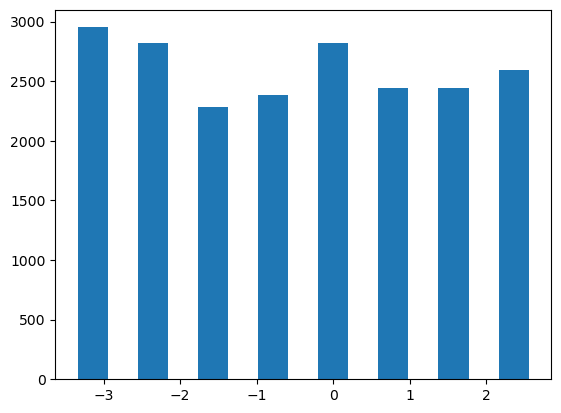

In [39]:
# Make 1D histogram of gradients based on angle
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)

sobel_mag = np.sqrt(sobelx**2 + sobely**2)

sobelx = sobelx / (sobel_mag + 1e-6)
sobely = sobely / (sobel_mag + 1e-6)

sobel_angle = np.arctan2(sobely, sobelx)

sobel_hist, sobel_bins = np.histogram(sobel_angle, bins=8, range=(-np.pi, np.pi))

plt.bar(sobel_bins[:-1], sobel_hist, width=np.pi/8)